this notebook computes trajectories using the backtrajectory-calculator package.
Environment: bt_env

In [ ]:
import cdsapi
import xarray as xr
import pandas as pd
import numpy as np
import glob
import os
import sys
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
sys.path.append('/home/jmayer/ACI_research/backtrajectory-calculator/')
from BT import compute_bt

In [ ]:
judge_results = pd.read_csv('/home/jmayer/ACI_research/Code/resources/judge_results_May-Aug.csv')

In [ ]:
judge_SEP = judge_results[(judge_results['lat_mid'] >= -25) & (judge_results['lat_mid'] <= -2.5) &
                                      (judge_results['lon_mid'] >= -95) & (judge_results['lon_mid'] <= -75)]
judge_SEP = judge_SEP[pd.to_datetime(judge_SEP['time_mid']) >= pd.to_datetime('2025-06-01')]

In [ ]:
judge_SEP

,along_track_mid,time_mid,lon_mid,lat_mid,lat_min,lat_max,ice_flag,cwp_skew,cwp_inhomogeneity,cloud_cover,cats,cert,orbit
2157,7329.5,2025-06-01 19:36:21.835411456,-85.359344,-5.623816,-6.094768,-5.054541,0.000000,3.668211,1.241621,0.458008,4,0.867524,05739E
2158,7457.5,2025-06-01 19:36:29.899475008,-85.457413,-6.145952,-6.616865,-5.572656,0.000000,2.844348,1.299847,0.442261,4,0.900620,05739E
2159,7585.5,2025-06-01 19:36:37.963538944,-85.555511,-6.668075,-7.138940,-6.094768,0.000000,2.838897,1.521417,0.242310,4,0.498289,05739E
2160,7713.5,2025-06-01 19:36:46.027606016,-85.653679,-7.190176,-7.660944,-6.616865,0.000000,2.595856,0.855041,0.202637,5,0.866147,05739E
2161,7841.5,2025-06-01 19:36:54.091673024,-85.752090,-7.712209,-8.182907,-7.138940,0.000000,4.197616,0.967148,0.314636,5,0.550978,05739E
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8888,10805.5,2025-08-31 19:42:52.828575872,-88.973877,-19.815862,-20.283984,-19.242703,0.350342,2.052217,0.845203,0.969604,3,0.774081,07155E
8889,10933.5,2025-08-31 19:43:00.892639936,-89.079163,-20.336534,-20.804462,-19.763390,0.338501,2.016538,0.649727,0.996277,0,0.979926,07155E
8890,11061.5,2025-08-31 19:43:08.956703040,-89.184990,-20.857090,-21.324853,-20.283984,0.052551,2.718789,0.867891,0.947083,3,0.544055,07155E
8891,11189.5,2025-08-31 19:43:17.020770496,-89.291214,-21.377560,-21.845175,-20.804462,0.002441,2.368745,1.096538,0.832764,3,0.631883,07155E


In [ ]:
judge_SEP = judge_SEP[pd.to_datetime(judge_SEP['time_mid']) >= pd.to_datetime('2025-08-01')]

# compute Backtrajectories

In [ ]:
def bt_dict_to_xr(bt, backwards, time_i):
    traj_ds = xr.Dataset()
    traj_ds['lat_traj'] = ('timestep', bt['lat_traj'][0])
    traj_ds['lon_traj'] = ('timestep', bt['lon_traj'][0])
    traj_ds['plev_traj'] = ('timestep', bt['plev_traj'][0])
    traj_ds['datetime_traj'] = ('timestep', bt['datetime_traj'][0])
    timestep = [i*6 for i in range(len(bt['lat_traj'][0]))]
    if backwards:
        timestep = [-t for t in timestep]
    traj_ds = traj_ds.assign_coords({'timestep': timestep})
    traj_ds = traj_ds.sortby('timestep')
    traj_ds = traj_ds.assign_coords({'time_startpoint': pd.to_datetime(time_i)})
    return traj_ds

In [ ]:
idx = 0
bt_SEP = None
#with xr.open_dataset('/home/jmayer/ACI_research/Code/resources/bt_SEP_partial.nc') as ds:
#    bt_SEP = ds.load()
    
failed_indices = []
for i in range(len(judge_SEP)):
    #for i in range(3):
    print(i)
    loni = judge_SEP['lon_mid'].values[i]
    lati = judge_SEP['lat_mid'].values[i]
    datei = pd.to_datetime(judge_SEP['time_mid'].values[i]).date().strftime('%Y-%m-%d')
    timei = pd.to_datetime(judge_SEP['time_mid'].values[i])

    try:
        bt_forward = compute_bt(lati=lati, 
                    loni=loni, 
                    datei=datei, 
                    start_hour=18, 
                    ndays=2,
                    backwards=False,
                    overwrite_files=True,)

        bt_backward = compute_bt(lati=lati, 
                    loni=loni, 
                    datei=datei, 
                    start_hour=18, 
                    ndays=2,
                    backwards=True,
                    overwrite_files=True,)

        bt_forward_ds = bt_dict_to_xr(bt_forward, backwards=False, time_i=timei)
        bt_backward_ds = bt_dict_to_xr(bt_backward, backwards=True, time_i=timei)
        bt = xr.concat([bt_backward_ds, bt_forward_ds], dim='timestep')
        bt = bt.drop_duplicates('timestep')
    except Exception as e:
        print(f'Error computing bt for index {i}, time {timei}, lat {lati}, lon {loni}: {e}')
        failed_indices.append(i)
        continue

    if bt_SEP is None:
        bt_SEP = bt
    else:
        bt_SEP = xr.concat([bt_SEP, bt], dim='time_startpoint')

    bt_SEP.to_netcdf(f'/home/jmayer/ACI_research/Code/resources/bt_SEP_partial.nc')
#bt_SEP.to_netcdf('/home/jmayer/ACI_research/Code/resources/bt_SEP.nc')
print(f'Failed indices: {failed_indices}')

0

Loading properties from:
	/home/jmayer/Object_Data/ERA5_data/2025/omega_975hPa_20250801.nc
2025-08-23 18:00 -----> 2025-08-23 18:01
Computing BT:
.....................................................................................


/home/jmayer/ACI_research/backtrajectory-calculator/BT.py:370: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  self.datetimes_iter = pd.date_range(self.fechai, self.fechaf,


-------------------------------------------------------------------------------------

Loading properties from:
	/home/jmayer/Object_Data/ERA5_data/2025/omega_975hPa_20250801.nc
2025-08-23 18:00 -----> 2025-08-23 18:01
Computing BT:
.....................................................................................


/home/jmayer/ACI_research/backtrajectory-calculator/BT.py:370: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  self.datetimes_iter = pd.date_range(self.fechai, self.fechaf,


-------------------------------------------------------------------------------------
1

Loading properties from:
	/home/jmayer/Object_Data/ERA5_data/2025/omega_975hPa_20250801.nc
2025-08-23 18:00 -----> 2025-08-23 18:01
Computing BT:
.....................................................................................


/home/jmayer/ACI_research/backtrajectory-calculator/BT.py:370: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  self.datetimes_iter = pd.date_range(self.fechai, self.fechaf,


... (1,055 outputs left out)

/home/jmayer/ACI_research/backtrajectory-calculator/BT.py:370: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  self.datetimes_iter = pd.date_range(self.fechai, self.fechaf,


-------------------------------------------------------------------------------------

Loading properties from:
	/home/jmayer/Object_Data/ERA5_data/2025/omega_975hPa_20250801.nc
2025-08-31 18:00 -----> 2025-08-31 18:01
Computing BT:
.....................................................................................


/home/jmayer/ACI_research/backtrajectory-calculator/BT.py:370: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  self.datetimes_iter = pd.date_range(self.fechai, self.fechaf,


-------------------------------------------------------------------------------------
Failed indices: []


<Axes: xlabel='lon_traj', ylabel='lat_traj'>

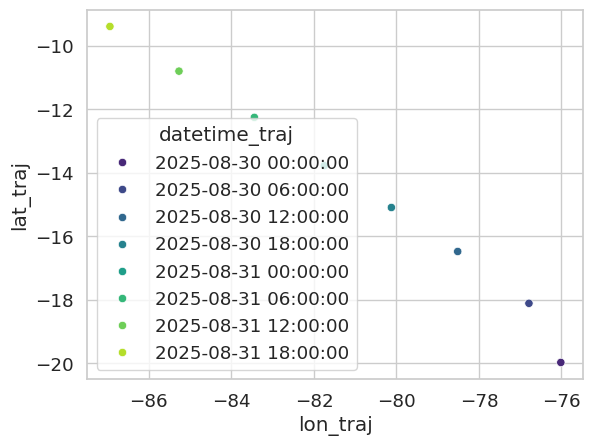

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.scatterplot(data=bt_SEP.isel(time_startpoint=-25), x='lon_traj', y='lat_traj', hue='datetime_traj', palette='viridis')